Pertemuan 2

In [1]:
!pip install Sastrawi -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 7.3 MB/s eta 0:00:00


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd
import re
import csv
import os

file_csv = "/content/drive/MyDrive/Colab Notebooks/Tugas praproses/berita.csv"

with open(file_csv, "r", encoding="utf-8-sig") as f:
    lines = f.read().splitlines()

columns = [
    "id", "source", "title", "image", "url",
    "content", "date", "embedding",
    "created_at", "updated_at", "summary"
]

def ambil_content(line):
    if line.startswith('"') and line.endswith('"'):
        line = line[1:-1]

    pola_image = re.search(
        r'https://statik\.tempo\.co/[^,]+\.jpg,',
        line
    )

    if not pola_image:
        return ""

    bagian = line[pola_image.end():]

    posisi_koma = bagian.find(",")

    if posisi_koma == -1:
        return ""

    bagian = bagian[posisi_koma + 1:]

    posisi_embedding = bagian.find(',""[')

    if posisi_embedding == -1:
        return ""

    content = bagian[:posisi_embedding]

    if content.startswith('""'):
        content = content[2:]

    if content.endswith('""'):
        content = content[:-2]

    return content

contents = []

for line in lines[1:]:
    contents.append(ambil_content(line))

df = pd.DataFrame({
    "content": contents
})

print("Jumlah berita:", len(df))
print("Jumlah content kosong:", df["content"].isna().sum())
print("\nContoh content:")
print(df["content"].head())

Jumlah berita: 50
Jumlah content kosong: 0

Contoh content:
0    TEMPO.CO, Jakarta - Anggota Komisi VII DPR RI ...
1    TEMPO.CO, Jakarta - Presiden Joko Widodo atau ...
2    INFO NASIONAL - Wakil Ketua MPR RI Dr. H. M. H...
3    TEMPO.CO, Jakarta - Tim Kedokteran dan Kesehat...
4    INFO NASIONAL - Ketua MPR RI sekaligus Ketua U...
Name: content, dtype: object


In [5]:
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

stemmer_factory = StemmerFactory()
stemmer = stemmer_factory.create_stemmer()

stopword_factory = StopWordRemoverFactory()
stopwords = set(stopword_factory.get_stop_words())

print("Stemmer dan stopword berhasil dibuat.")
print("Jumlah stopword:", len(stopwords))

Stemmer dan stopword berhasil dibuat.
Jumlah stopword: 123


In [6]:
raw_text = " ".join(df["content"].astype(str).tolist())

print("Jumlah karakter:", len(raw_text))
print("\nContoh teks:")
print(raw_text[:500])

Jumlah karakter: 157130

Contoh teks:
TEMPO.CO, Jakarta - Anggota Komisi VII DPR RI Rofik Hananto menyayangkan terjadinya insiden kebakaran yang disebabkan oleh bocornya depo Plumpang, Jakarta Utara, pada Jumat, 3 Maret 2023.""""Turut berbela sungkawa terhadap masyarakat sipil yang terdampak, apalagi ini daerah padat penduduk. Pertamina harus tanggung jawab,"""" kata dia dalam keterangan di Jakarta Sabtu, 4 Maret 2024.Rofik mengatakan Pertamina serta pihak terkait harus memastikan keselamatan dan keamanan warga yang tinggal di sekit


In [7]:

df['content'] = df['content'].fillna('').astype(str)

raw_text = " ".join(df['content'].tolist())

print("Jumlah karakter:", len(raw_text))
print("Contoh isi berita:", raw_text[:500])

tokens_raw = re.findall(r'\S+', raw_text)

casefold_text = raw_text.lower()
tokens_casefold = re.findall(r'\S+', casefold_text)

tokens_tokenisasi = re.findall(
    r'\b[a-zA-Z]+\b',
    casefold_text
)

tokens_stopword = [
    word for word in tokens_tokenisasi
    if word not in stopwords
]

tokens_stemming = [
    stemmer.stem(word)
    for word in tokens_stopword
]

def hitung_token_tipe(tokens):
    return len(tokens), len(set(tokens))

token_raw, tipe_raw = hitung_token_tipe(tokens_raw)
token_casefold, tipe_casefold = hitung_token_tipe(tokens_casefold)
token_tokenisasi, tipe_tokenisasi = hitung_token_tipe(tokens_tokenisasi)
token_stopword, tipe_stopword = hitung_token_tipe(tokens_stopword)
token_stemming, tipe_stemming = hitung_token_tipe(tokens_stemming)

hasil = pd.DataFrame({
    "Tahap": [
        "Teks mentah",
        "Case folding",
        "Tokenisasi",
        "Stopword removal",
        "Stemming"
    ],
    "Jumlah Token": [
        token_raw,
        token_casefold,
        token_tokenisasi,
        token_stopword,
        token_stemming
    ],
    "Jumlah Tipe": [
        tipe_raw,
        tipe_casefold,
        tipe_tokenisasi,
        tipe_stopword,
        tipe_stemming
    ]
})

display(hasil)

Jumlah karakter: 157130
Contoh isi berita: TEMPO.CO, Jakarta - Anggota Komisi VII DPR RI Rofik Hananto menyayangkan terjadinya insiden kebakaran yang disebabkan oleh bocornya depo Plumpang, Jakarta Utara, pada Jumat, 3 Maret 2023.""""Turut berbela sungkawa terhadap masyarakat sipil yang terdampak, apalagi ini daerah padat penduduk. Pertamina harus tanggung jawab,"""" kata dia dalam keterangan di Jakarta Sabtu, 4 Maret 2024.Rofik mengatakan Pertamina serta pihak terkait harus memastikan keselamatan dan keamanan warga yang tinggal di sekit


,Tahap,Jumlah Token,Jumlah Tipe
0,Teks mentah,20785,5763
1,Case folding,20785,5300
2,Tokenisasi,20851,3719
3,Stopword removal,15927,3617
4,Stemming,15927,2613


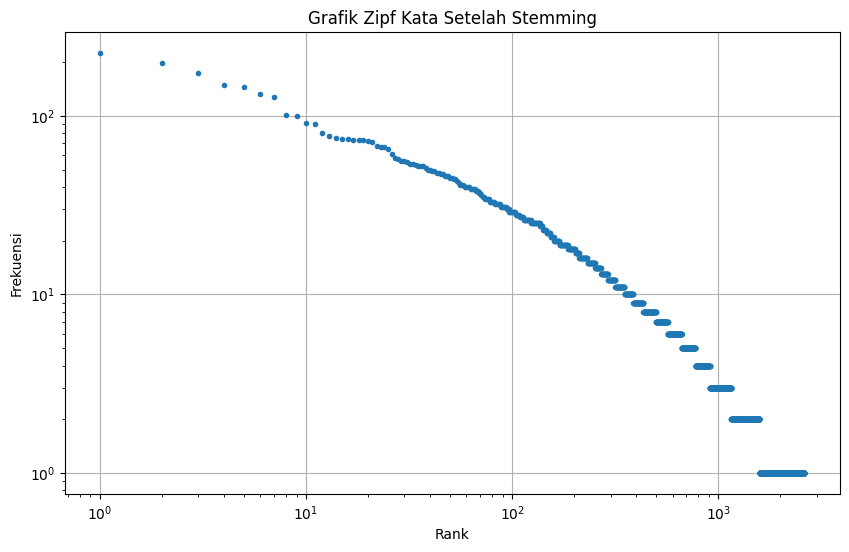

In [8]:
from collections import Counter
import matplotlib.pyplot as plt

frekuensi_kata = Counter(tokens_stemming)

frekuensi = sorted(frekuensi_kata.values(), reverse=True)

rank = range(1, len(frekuensi) + 1)

plt.figure(figsize=(10, 6))

plt.loglog(rank, frekuensi, marker='.', linestyle='none')

plt.xlabel("Rank")
plt.ylabel("Frekuensi")
plt.title("Grafik Zipf Kata Setelah Stemming")
plt.grid(True)

plt.show()

# Bagian Baru

In [9]:
df = df.head(50).copy()

df['content'] = df['content'].fillna('').astype(str)

documents = {}

for i, content in enumerate(df['content']):
    documents[i] = content

print("Jumlah dokumen:", len(documents))
print("Contoh dokumen 0:")
print(documents[0][:500])

Jumlah dokumen: 50
Contoh dokumen 0:
TEMPO.CO, Jakarta - Anggota Komisi VII DPR RI Rofik Hananto menyayangkan terjadinya insiden kebakaran yang disebabkan oleh bocornya depo Plumpang, Jakarta Utara, pada Jumat, 3 Maret 2023.""""Turut berbela sungkawa terhadap masyarakat sipil yang terdampak, apalagi ini daerah padat penduduk. Pertamina harus tanggung jawab,"""" kata dia dalam keterangan di Jakarta Sabtu, 4 Maret 2024.Rofik mengatakan Pertamina serta pihak terkait harus memastikan keselamatan dan keamanan warga yang tinggal di sekit


In [10]:
import re

processed_documents = {}

for doc_id, content in documents.items():

    text = content.lower()

    tokens = re.findall(r'\b[a-zA-Z]+\b', text)

    tokens = [
        word for word in tokens
        if word not in stopwords
    ]

    tokens = [
        stemmer.stem(word)
        for word in tokens
    ]

    processed_documents[doc_id] = tokens

print("Contoh hasil preprocessing dokumen 0:")
print(processed_documents[0][:30])

Contoh hasil preprocessing dokumen 0:
['tempo', 'co', 'jakarta', 'anggota', 'komisi', 'vii', 'dpr', 'ri', 'rofik', 'hananto', 'sayang', 'jadi', 'insiden', 'bakar', 'sebab', 'bocor', 'depo', 'plumpang', 'jakarta', 'utara', 'jumat', 'maret', 'turut', 'bela', 'sungkawa', 'masyarakat', 'sipil', 'dampak', 'daerah', 'padat']


In [11]:
from collections import defaultdict

index = defaultdict(list)

for doc_id, tokens in processed_documents.items():

    unique_terms = set(tokens)

    for term in unique_terms:
        index[term].append(doc_id)

for term in index:
    index[term] = sorted(index[term])

inverted_index = {}

for term, postings in index.items():
    inverted_index[term] = {
        "df": len(postings),
        "postings": postings
    }

print("Jumlah term:", len(inverted_index))

contoh_term = "pertamina"

if contoh_term in inverted_index:
    print("\nTerm:", contoh_term)
    print("DF:", inverted_index[contoh_term]["df"])
    print("Posting list:", inverted_index[contoh_term]["postings"])
else:
    print("Term tidak ditemukan.")

Jumlah term: 2613

Term: pertamina
DF: 9
Posting list: [0, 1, 3, 5, 8, 9, 10, 17, 37]


In [12]:
def intersect(posting1, posting2):

    hasil = []

    i = 0
    j = 0

    while i < len(posting1) and j < len(posting2):

        if posting1[i] == posting2[j]:
            hasil.append(posting1[i])
            i += 1
            j += 1

        elif posting1[i] < posting2[j]:
            i += 1

        else:
            j += 1

    return hasil


In [13]:
def get_postings(term):
    term = term.lower()

    if term in inverted_index:
        return inverted_index[term]["postings"]

    return []


def boolean_and(term1, term2):
    posting1 = get_postings(term1)
    posting2 = get_postings(term2)

    return intersect(posting1, posting2)


def boolean_or(term1, term2):
    posting1 = get_postings(term1)
    posting2 = get_postings(term2)

    return sorted(set(posting1) | set(posting2))

def boolean_not(term):
    semua_dokumen = set(documents.keys())
    posting = set(get_postings(term))

    return sorted(semua_dokumen - posting)


def boolean_query(query):

    query = query.lower().strip()

    if query.startswith("not "):
        term = query[4:].strip()
        return boolean_not(term)

    if " and " in query:
        term1, term2 = query.split(" and ", 1)
        return boolean_and(term1.strip(), term2.strip())

    if " or " in query:
        term1, term2 = query.split(" or ", 1)
        return boolean_or(term1.strip(), term2.strip())

    return get_postings(query)

# Bagian Baru

In [14]:
for doc_id, content in documents.items():
    print(f"Dokumen {doc_id}")
    print(content[:300])
    print("-" * 80)

Dokumen 0
TEMPO.CO, Jakarta - Anggota Komisi VII DPR RI Rofik Hananto menyayangkan terjadinya insiden kebakaran yang disebabkan oleh bocornya depo Plumpang, Jakarta Utara, pada Jumat, 3 Maret 2023.""""Turut berbela sungkawa terhadap masyarakat sipil yang terdampak, apalagi ini daerah padat penduduk. Pertamina
--------------------------------------------------------------------------------
Dokumen 1
TEMPO.CO, Jakarta - Presiden Joko Widodo atau Jokowi memerintahkan Wakil Presiden Ma'ruf Amin untuk meninjau langsung lokasi kebakaran depo Pertamina di Plumpang, Jakarta Utara. Kebakaran besar di lokasi tersebut terjadi pada Jumat malam, 3 Maret 2023, dan mengakibatkan belasan warga di sekitar depo
--------------------------------------------------------------------------------
Dokumen 2
INFO NASIONAL - Wakil Ketua MPR RI Dr. H. M. Hidayat Nur Wahid MA., atau HNW menerima kunjungan perwakilan korban kasus biro perjalanan Haji dan Umroh First Travel, yang tergabung dalam Paguyuban First Trav

In [15]:
queries = [
    "kebakaran depo Pertamina Plumpang",
    "penundaan Pemilu 2024",
    "Prabowo Subianto Surya Paloh",
    "KPU banding putusan pemilu",
    "Rafael Alun Trisambodo KPK",
    "Anies AHY Pilpres 2024",
    "Sri Mulyani keuangan",
    "Syahrul Yasin Limpo pertanian",
    "Komnas HAM Wamena",
    "Erick Thohir"
]

relevant_docs = {
    1: [0, 1, 3, 5, 8, 9, 10, 17, 37],
    2: [7, 11, 13, 16, 18, 20, 21, 23, 24, 26, 29, 36],
    3: [12, 14],
    4: [13, 18, 21, 26],
    5: [27, 28, 46],
    6: [38, 41],
    7: [6, 35],
    8: [25, 31, 42],
    9: [15],
    10: [5, 10, 37, 49]
}

for i, query in enumerate(queries, 1):
    print(f"Query {i}: {query}")
    print("Dokumen relevan:", relevant_docs[i])
    print()

Query 1: kebakaran depo Pertamina Plumpang
Dokumen relevan: [0, 1, 3, 5, 8, 9, 10, 17, 37]

Query 2: penundaan Pemilu 2024
Dokumen relevan: [7, 11, 13, 16, 18, 20, 21, 23, 24, 26, 29, 36]

Query 3: Prabowo Subianto Surya Paloh
Dokumen relevan: [12, 14]

Query 4: KPU banding putusan pemilu
Dokumen relevan: [13, 18, 21, 26]

Query 5: Rafael Alun Trisambodo KPK
Dokumen relevan: [27, 28, 46]

Query 6: Anies AHY Pilpres 2024
Dokumen relevan: [38, 41]

Query 7: Sri Mulyani keuangan
Dokumen relevan: [6, 35]

Query 8: Syahrul Yasin Limpo pertanian
Dokumen relevan: [25, 31, 42]

Query 9: Komnas HAM Wamena
Dokumen relevan: [15]

Query 10: Erick Thohir
Dokumen relevan: [5, 10, 37, 49]



In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

processed_texts = [
    " ".join(processed_documents[i])
    for i in range(len(documents))
]

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(processed_texts)

print("Jumlah dokumen:", tfidf_matrix.shape[0])
print("Jumlah term:", tfidf_matrix.shape[1])


def preprocess_query(query):
    text = query.lower()

    tokens = re.findall(r'\b[a-zA-Z]+\b', text)

    tokens = [
        word for word in tokens
        if word not in stopwords
    ]

    tokens = [
        stemmer.stem(word)
        for word in tokens
    ]

    return tokens


def ranking_tfidf(query, top_k=10):

    query_tokens = preprocess_query(query)
    query_text = " ".join(query_tokens)

    query_vector = vectorizer.transform([query_text])

    scores = cosine_similarity(
        query_vector,
        tfidf_matrix
    ).flatten()

    ranking = scores.argsort()[::-1][:top_k]

    return [
        (int(doc_id), float(scores[doc_id]))
        for doc_id in ranking
    ]

Jumlah dokumen: 50
Jumlah term: 2599


In [17]:
hasil_tfidf = {}

for i, query in enumerate(queries, 1):

    hasil_tfidf[i] = ranking_tfidf(query, top_k=10)

    print("=" * 60)
    print(f"Query {i}: {query}")

    for rank, (doc_id, score) in enumerate(hasil_tfidf[i], 1):
        print(
            f"{rank}. Dokumen {doc_id} "
            f"- Score: {score:.4f}"
        )

Query 1: kebakaran depo Pertamina Plumpang
1. Dokumen 10 - Score: 0.5478
2. Dokumen 5 - Score: 0.4956
3. Dokumen 0 - Score: 0.4885
4. Dokumen 17 - Score: 0.4521
5. Dokumen 1 - Score: 0.4458
6. Dokumen 9 - Score: 0.4323
7. Dokumen 8 - Score: 0.3854
8. Dokumen 37 - Score: 0.3632
9. Dokumen 3 - Score: 0.2954
10. Dokumen 15 - Score: 0.0130
Query 2: penundaan Pemilu 2024
1. Dokumen 13 - Score: 0.4784
2. Dokumen 16 - Score: 0.4328
3. Dokumen 29 - Score: 0.4202
4. Dokumen 23 - Score: 0.3834
5. Dokumen 21 - Score: 0.3380
6. Dokumen 18 - Score: 0.3206
7. Dokumen 11 - Score: 0.2723
8. Dokumen 24 - Score: 0.2384
9. Dokumen 26 - Score: 0.2307
10. Dokumen 36 - Score: 0.2228
Query 3: Prabowo Subianto Surya Paloh
1. Dokumen 12 - Score: 0.5143
2. Dokumen 14 - Score: 0.4694
3. Dokumen 30 - Score: 0.3573
4. Dokumen 38 - Score: 0.0516
5. Dokumen 41 - Score: 0.0516
6. Dokumen 16 - Score: 0.0292
7. Dokumen 1 - Score: 0.0187
8. Dokumen 40 - Score: 0.0168
9. Dokumen 47 - Score: 0.0153
10. Dokumen 48 - Score:

In [19]:
from collections import Counter
import math

N = len(documents)

doc_lengths = {
    doc_id: len(tokens)
    for doc_id, tokens in processed_documents.items()
}

avgdl = sum(doc_lengths.values()) / N

doc_term_freq = {
    doc_id: Counter(tokens)
    for doc_id, tokens in processed_documents.items()
}

term_df = {
    term: info["df"]
    for term, info in inverted_index.items()
}


def bm25_score(query, doc_id, k1=1.2, b=0.75):

    query_tokens = preprocess_query(query)

    score = 0

    doc_length = doc_lengths[doc_id]

    for term in set(query_tokens):

        if term not in term_df:
            continue

        tf = doc_term_freq[doc_id][term]

        df = term_df[term]

        idf = math.log(
            ((N - df + 0.5) / (df + 0.5)) + 1
        )

        numerator = tf * (k1 + 1)

        denominator = (
            tf +
            k1 * (
                1 - b +
                b * (doc_length / avgdl)
            )
        )

        score += idf * (numerator / denominator)

    return score


def ranking_bm25(query, k1=1.2, b=0.75, top_k=10):

    scores = {}

    for doc_id in documents.keys():

        scores[doc_id] = bm25_score(
            query,
            doc_id,
            k1,
            b
        )

    ranking = sorted(
        scores.items(),
        key=lambda x: x[1],
        reverse=True
    )[:top_k]

    return ranking


print("Jumlah dokumen:", N)
print("Rata-rata panjang dokumen:", round(avgdl, 2))
print("Parameter BM25: k1 = 1.2, b = 0.75")

Jumlah dokumen: 50
Rata-rata panjang dokumen: 318.54
Parameter BM25: k1 = 1.2, b = 0.75


In [20]:
hasil_bm25 = {}

for i, query in enumerate(queries, 1):

    hasil_bm25[i] = ranking_bm25(
        query,
        k1=1.2,
        b=0.75,
        top_k=10
    )

    print("=" * 60)
    print(f"Query {i}: {query}")

    for rank, (doc_id, score) in enumerate(
        hasil_bm25[i], 1
    ):
        print(
            f"{rank}. Dokumen {doc_id} "
            f"- Score: {score:.4f}"
        )

Query 1: kebakaran depo Pertamina Plumpang
1. Dokumen 10 - Score: 12.7599
2. Dokumen 0 - Score: 12.5543
3. Dokumen 37 - Score: 12.4293
4. Dokumen 5 - Score: 12.4059
5. Dokumen 17 - Score: 12.3992
6. Dokumen 9 - Score: 12.3530
7. Dokumen 8 - Score: 12.2267
8. Dokumen 1 - Score: 12.0284
9. Dokumen 3 - Score: 11.5783
10. Dokumen 15 - Score: 1.7018
Query 2: penundaan Pemilu 2024
1. Dokumen 23 - Score: 5.1404
2. Dokumen 13 - Score: 5.0910
3. Dokumen 16 - Score: 5.0707
4. Dokumen 29 - Score: 5.0635
5. Dokumen 18 - Score: 4.9208
6. Dokumen 24 - Score: 4.7981
7. Dokumen 11 - Score: 4.7863
8. Dokumen 36 - Score: 4.7830
9. Dokumen 21 - Score: 4.6689
10. Dokumen 26 - Score: 4.6491
Query 3: Prabowo Subianto Surya Paloh
1. Dokumen 12 - Score: 16.8380
2. Dokumen 14 - Score: 16.3347
3. Dokumen 30 - Score: 15.4766
4. Dokumen 38 - Score: 5.6534
5. Dokumen 41 - Score: 5.6534
6. Dokumen 16 - Score: 3.5330
7. Dokumen 40 - Score: 2.1071
8. Dokumen 47 - Score: 2.0364
9. Dokumen 1 - Score: 1.9537
10. Dokumen

In [21]:
perbandingan = []

for i, query in enumerate(queries, 1):

    ranking_tfidf = [
        doc_id for doc_id, score in hasil_tfidf[i]
    ]

    ranking_bm25 = [
        doc_id for doc_id, score in hasil_bm25[i]
    ]

    perbandingan.append({
        "Query": i,
        "Kata Kunci": query,
        "Ranking TF-IDF": ranking_tfidf,
        "Ranking BM25": ranking_bm25,
        "Ranking Berbeda": ranking_tfidf != ranking_bm25
    })

df_perbandingan = pd.DataFrame(perbandingan)

display(df_perbandingan)

,Query,Kata Kunci,Ranking TF-IDF,Ranking BM25,Ranking Berbeda
0,1,kebakaran depo Pertamina Plumpang,"[10, 5, 0, 17, 1, 9, 8, 37, 3, 15]","[10, 0, 37, 5, 17, 9, 8, 1, 3, 15]",True
1,2,penundaan Pemilu 2024,"[13, 16, 29, 23, 21, 18, 11, 24, 26, 36]","[23, 13, 16, 29, 18, 24, 11, 36, 21, 26]",True
2,3,Prabowo Subianto Surya Paloh,"[12, 14, 30, 38, 41, 16, 1, 40, 47, 48]","[12, 14, 30, 38, 41, 16, 40, 47, 1, 0]",True
3,4,KPU banding putusan pemilu,"[18, 13, 21, 26, 29, 11, 23, 36, 24, 16]","[18, 26, 13, 21, 29, 36, 11, 23, 24, 7]",True
4,5,Rafael Alun Trisambodo KPK,"[46, 27, 28, 39, 32, 35, 6, 43, 48, 49]","[46, 27, 28, 39, 32, 35, 6, 0, 1, 2]",True
5,6,Anies AHY Pilpres 2024,"[38, 41, 30, 9, 14, 13, 12, 34, 7, 49]","[38, 41, 30, 14, 9, 34, 12, 13, 7, 0]",True
6,7,Sri Mulyani keuangan,"[35, 6, 27, 32, 46, 47, 28, 40, 2, 20]","[35, 6, 32, 27, 47, 46, 28, 40, 2, 20]",True
7,8,Syahrul Yasin Limpo pertanian,"[25, 42, 43, 31, 44, 5, 10, 49, 48, 47]","[42, 25, 44, 31, 43, 5, 10, 0, 1, 2]",True
8,9,Komnas HAM Wamena,"[15, 4, 7, 47, 45, 44, 43, 46, 41, 40]","[15, 4, 7, 0, 1, 2, 3, 5, 6, 8]",True
9,10,Erick Thohir,"[37, 49, 17, 10, 1, 5, 48, 47, 45, 46]","[37, 49, 17, 10, 1, 5, 0, 2, 3, 4]",True


In [22]:
for _, row in df_perbandingan.iterrows():

    if row["Ranking Berbeda"]:

        print("=" * 70)
        print(f"Query {row['Query']}: {row['Kata Kunci']}")

        print("\nTF-IDF:")
        print(row["Ranking TF-IDF"])

        print("\nBM25:")
        print(row["Ranking BM25"])

Query 1: kebakaran depo Pertamina Plumpang

TF-IDF:
[10, 5, 0, 17, 1, 9, 8, 37, 3, 15]

BM25:
[10, 0, 37, 5, 17, 9, 8, 1, 3, 15]
Query 2: penundaan Pemilu 2024

TF-IDF:
[13, 16, 29, 23, 21, 18, 11, 24, 26, 36]

BM25:
[23, 13, 16, 29, 18, 24, 11, 36, 21, 26]
Query 3: Prabowo Subianto Surya Paloh

TF-IDF:
[12, 14, 30, 38, 41, 16, 1, 40, 47, 48]

BM25:
[12, 14, 30, 38, 41, 16, 40, 47, 1, 0]
Query 4: KPU banding putusan pemilu

TF-IDF:
[18, 13, 21, 26, 29, 11, 23, 36, 24, 16]

BM25:
[18, 26, 13, 21, 29, 36, 11, 23, 24, 7]
Query 5: Rafael Alun Trisambodo KPK

TF-IDF:
[46, 27, 28, 39, 32, 35, 6, 43, 48, 49]

BM25:
[46, 27, 28, 39, 32, 35, 6, 0, 1, 2]
Query 6: Anies AHY Pilpres 2024

TF-IDF:
[38, 41, 30, 9, 14, 13, 12, 34, 7, 49]

BM25:
[38, 41, 30, 14, 9, 34, 12, 13, 7, 0]
Query 7: Sri Mulyani keuangan

TF-IDF:
[35, 6, 27, 32, 46, 47, 28, 40, 2, 20]

BM25:
[35, 6, 32, 27, 47, 46, 28, 40, 2, 20]
Query 8: Syahrul Yasin Limpo pertanian

TF-IDF:
[25, 42, 43, 31, 44, 5, 10, 49, 48, 47]

BM25:
[42

In [23]:
def hitung_ranking_bm25(query, k1=1.2, b=0.75, top_k=10):
    scores = {}

    for doc_id in documents.keys():
        scores[doc_id] = bm25_score(query, doc_id, k1, b)

    ranking = sorted(
        scores.items(),
        key=lambda x: x[1],
        reverse=True
    )[:top_k]

    return ranking


query_uji = queries[0]

print("Query yang digunakan untuk pengujian parameter:")
print(query_uji)

print("\n" + "=" * 60)
print("PENGARUH k1")
print("=" * 60)

for k1 in [0.5, 1.2, 2.0]:
    hasil = hitung_ranking_bm25(
        query_uji,
        k1=k1,
        b=0.75,
        top_k=10
    )

    ranking = [doc_id for doc_id, score in hasil]

    print(f"k1 = {k1}")
    print("Ranking:", ranking)
    print()


print("=" * 60)
print("PENGARUH b")
print("=" * 60)

for b in [0.25, 0.75, 1.0]:
    hasil = hitung_ranking_bm25(
        query_uji,
        k1=1.2,
        b=b,
        top_k=10
    )

    ranking = [doc_id for doc_id, score in hasil]

    print(f"b = {b}")
    print("Ranking:", ranking)
    print()

Query yang digunakan untuk pengujian parameter:
kebakaran depo Pertamina Plumpang

PENGARUH k1
k1 = 0.5
Ranking: [10, 0, 37, 17, 5, 9, 8, 1, 3, 15]

k1 = 1.2
Ranking: [10, 0, 37, 5, 17, 9, 8, 1, 3, 15]

k1 = 2.0
Ranking: [10, 0, 37, 5, 17, 9, 8, 1, 3, 15]

PENGARUH b
b = 0.25
Ranking: [9, 10, 17, 5, 0, 1, 8, 37, 3, 15]

b = 0.75
Ranking: [10, 0, 37, 5, 17, 9, 8, 1, 3, 15]

b = 1.0
Ranking: [37, 10, 0, 5, 8, 17, 1, 9, 3, 15]



In [24]:
hasil_evaluasi = []

for i, query in enumerate(queries, 1):
    relevan = set(relevant_docs[i])

    ranking_tf = [doc_id for doc_id, score in hasil_tfidf[i]]
    ranking_bm = [doc_id for doc_id, score in hasil_bm25[i]]

    precision_tf = sum(doc in relevan for doc in ranking_tf) / 10
    precision_bm = sum(doc in relevan for doc in ranking_bm) / 10

    posisi_tf = next(
        (rank for rank, doc in enumerate(ranking_tf, 1) if doc in relevan),
        None
    )

    posisi_bm = next(
        (rank for rank, doc in enumerate(ranking_bm, 1) if doc in relevan),
        None
    )

    hasil_evaluasi.append({
        "Query": i,
        "Precision@10 TF-IDF": precision_tf,
        "Precision@10 BM25": precision_bm,
        "Posisi Relevan Pertama TF-IDF": posisi_tf,
        "Posisi Relevan Pertama BM25": posisi_bm
    })

df_evaluasi = pd.DataFrame(hasil_evaluasi)

display(df_evaluasi)

print("Rata-rata Precision@10 TF-IDF:",
      round(df_evaluasi["Precision@10 TF-IDF"].mean(), 3))

print("Rata-rata Precision@10 BM25:",
      round(df_evaluasi["Precision@10 BM25"].mean(), 3))

,Query,Precision@10 TF-IDF,Precision@10 BM25,Posisi Relevan Pertama TF-IDF,Posisi Relevan Pertama BM25
0,1,0.9,0.9,1,1
1,2,1.0,1.0,1,1
2,3,0.2,0.2,1,1
3,4,0.4,0.4,1,1
4,5,0.3,0.3,1,1
5,6,0.2,0.2,1,1
6,7,0.2,0.2,1,1
7,8,0.3,0.3,1,1
8,9,0.1,0.1,1,1
9,10,0.4,0.4,1,1


Rata-rata Precision@10 TF-IDF: 0.4
Rata-rata Precision@10 BM25: 0.4
